# Tugas - Klasifikasi dengan Decision Tree

| Nama | NRP |
|------|-----|
| Fahmi Alfayadh | 5054251015 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model Decision Tree Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja Decision Tree secara praktik, khususnya:
1. Perbedaan hasil antara kriteria split Gini Impurity dan Entropy
2. Pengaruh regularisasi (max_depth) terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model.
3. Eksperimen Model
   - Bangun model Decision Tree dengan kriteria Gini dan Entropy.
   - Lakukan eksperimen regularisasi dengan variasi nilai max_depth.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [81]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [82]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
df = pd.read_csv('dataset/bankruptcy.csv')
display(df.head())


print()
print("================================")
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("Tipe data:")
print(df.dtypes)

print()
print("================================")
print("Statistik deskriptif:")
print(df.describe())

print()
print("================================")
print("Jumlah missing value:")
print(df.isnull().sum())

print()
print("================================")
print("Jumlah Duplikasi:")
print(df.duplicated().sum())


,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490



Jumlah baris: 6819
Jumlah kolom: 96
Tipe data:
Bankrupt?                                                     int64
 ROA(C) before interest and depreciation before interest    float64
 ROA(A) before interest and % after tax                     float64
 ROA(B) before interest and depreciation after tax          float64
 Operating Gross Margin                                     float64
                                                             ...   
 Liability to Equity                                        float64
 Degree of Financial Leverage (DFL)                         float64
 Interest Coverage Ratio (Interest expense to EBIT)         float64
 Net Income Flag                                              int64
 Equity to Liability                                        float64
Length: 96, dtype: object

Statistik deskriptif:
         Bankrupt?   ROA(C) before interest and depreciation before interest  \
count  6819.000000                                        6819.000000      

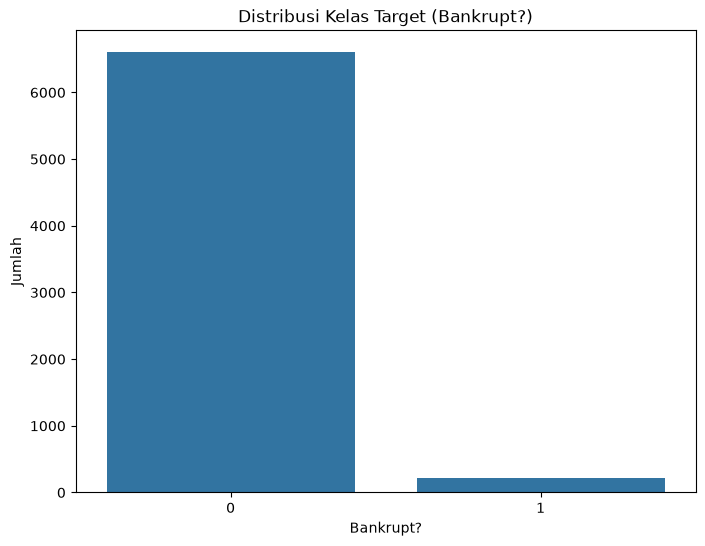

In [83]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
plt.figure(figsize=(8, 6))
sns.countplot(x='Bankrupt?', data=df)
plt.title('Distribusi Kelas Target (Bankrupt?)')
plt.xlabel('Bankrupt?')
plt.ylabel('Jumlah')
plt.show()

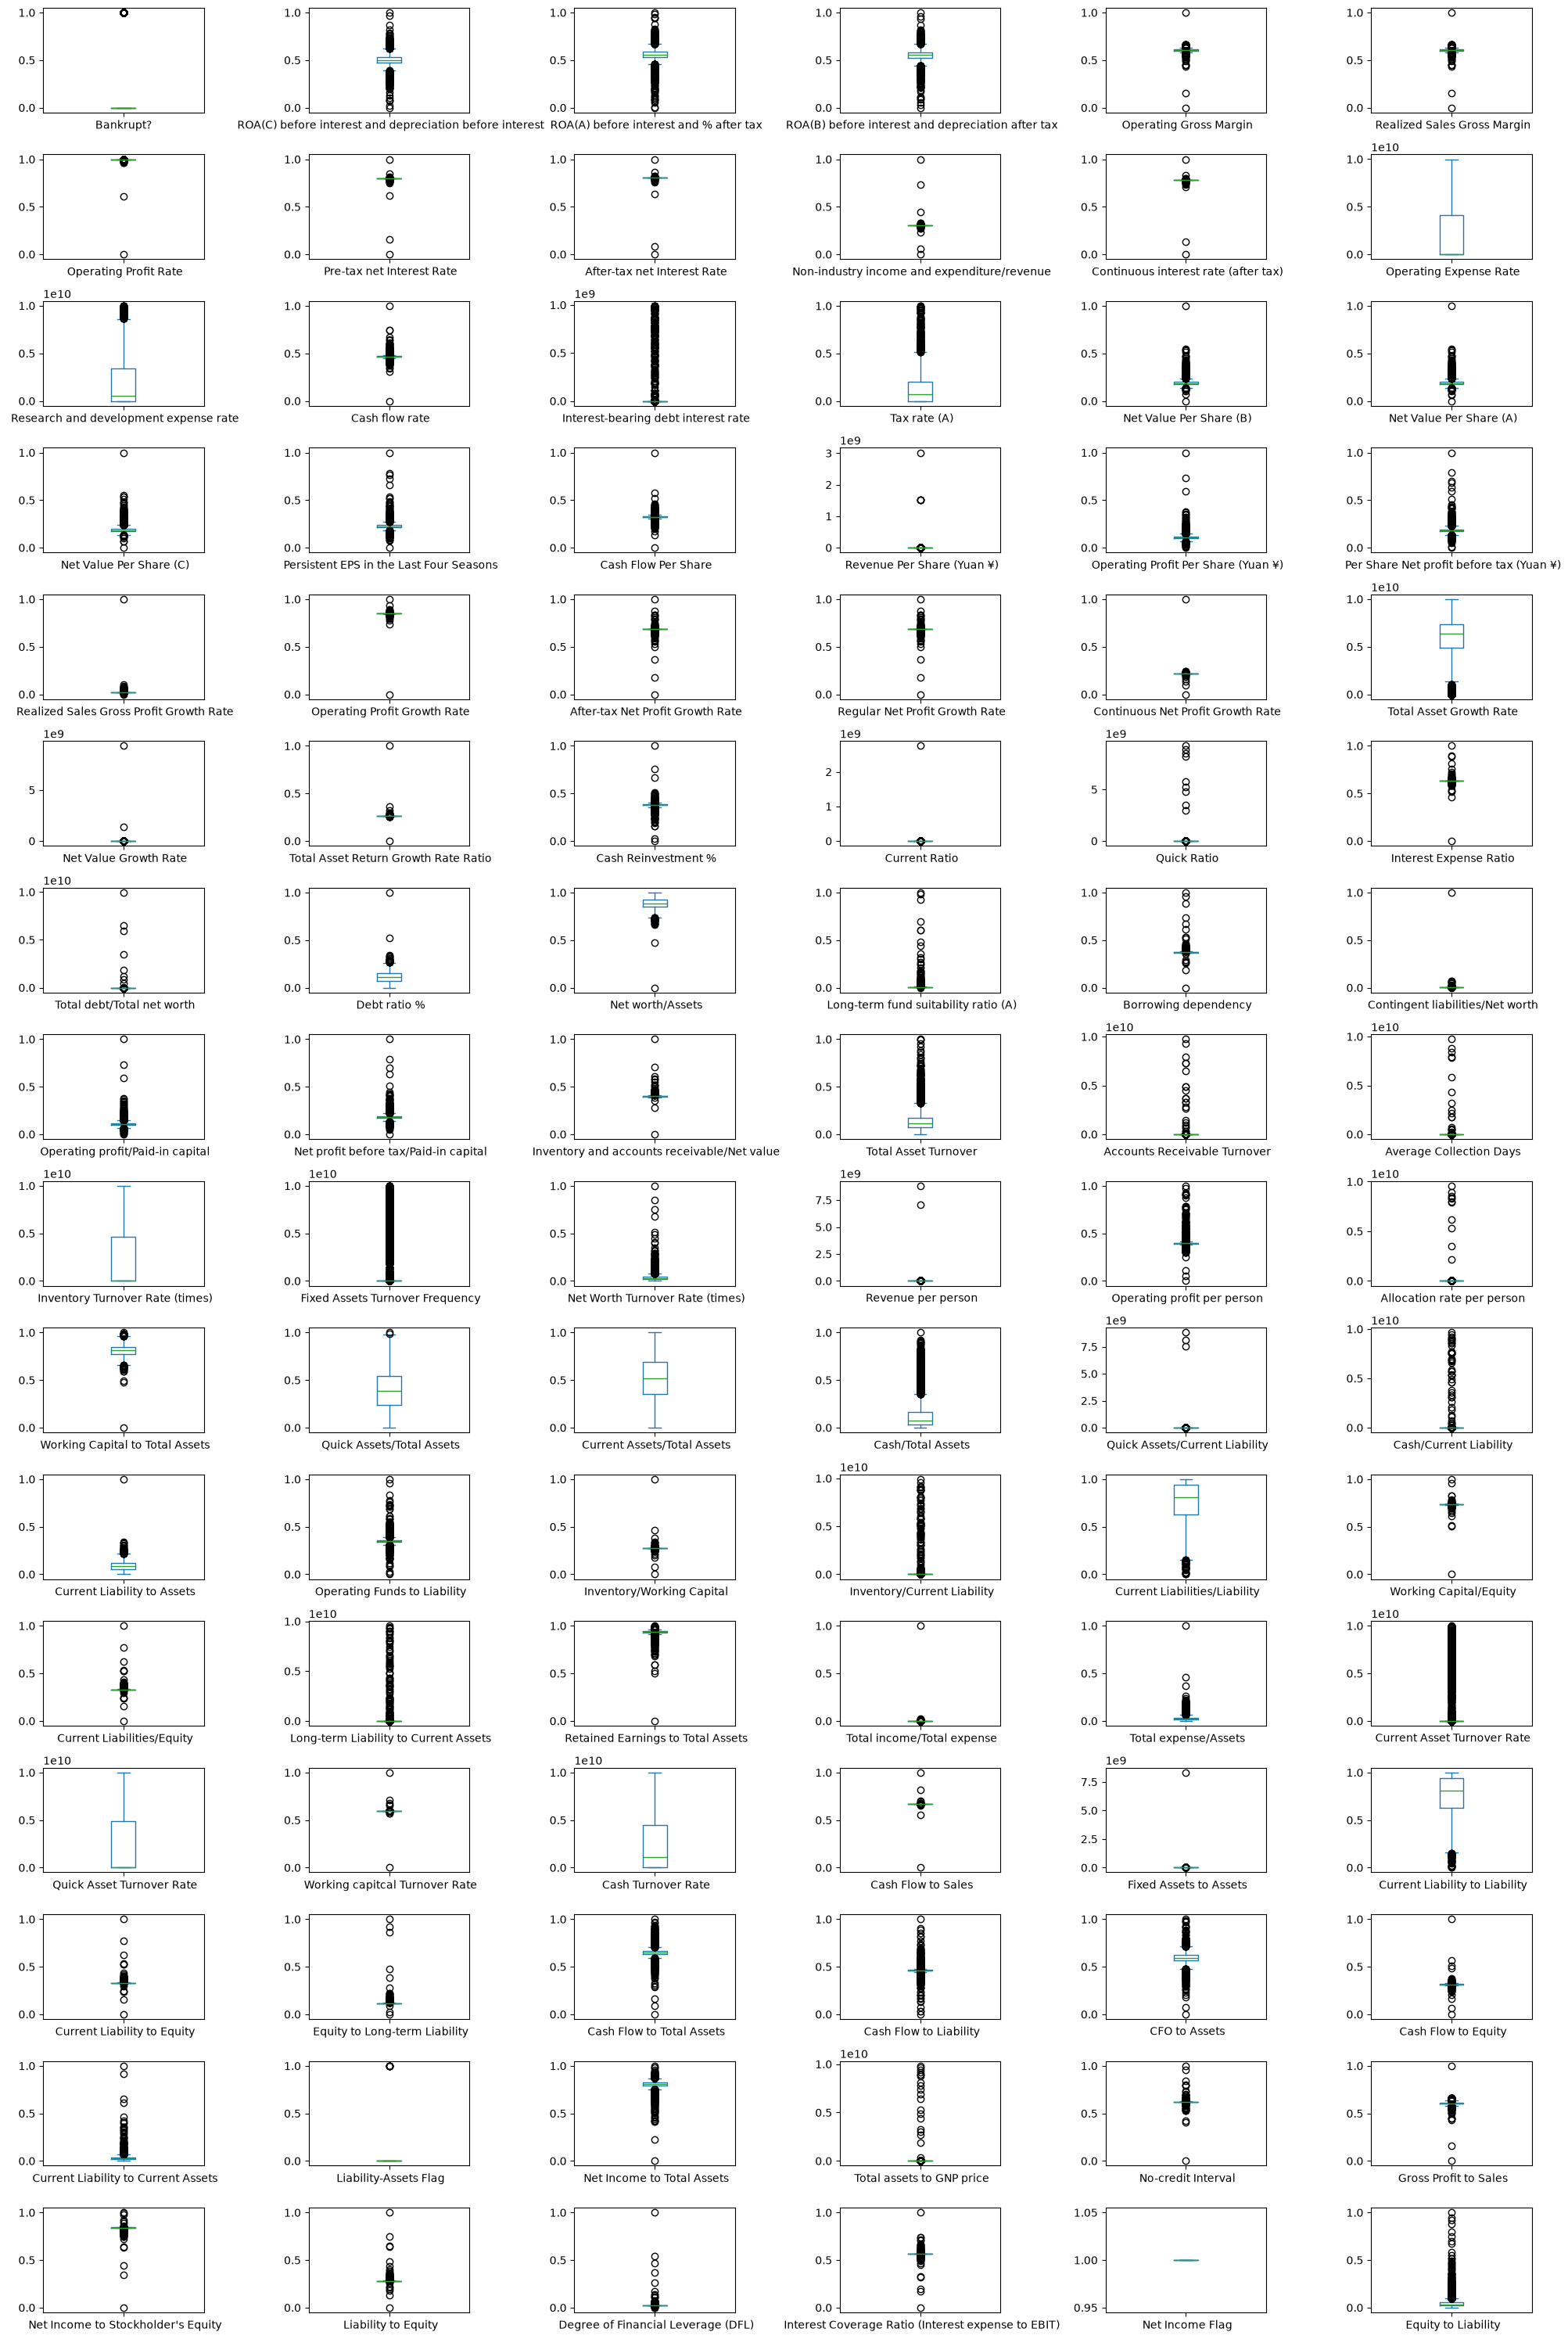

In [84]:
#nampilin boxplot
df.plot(kind='box', subplots=True, layout=(16, 6), figsize=(20, 30), sharey=False)
plt.tight_layout()
plt.show()


In [85]:
'''#hapus outlier extreme tiap kolom
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1


print("================================ SSETELAH DIHAPUS OUTLIER =================================")
df_cleaned = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]
df_cleaned.plot(kind='box', subplots=True, layout=(16, 6), figsize=(20, 30), sharey=False)
plt.tight_layout()'''

'#hapus outlier extreme tiap kolom\nQ1 = df.quantile(0.25)\nQ3 = df.quantile(0.75)\nIQR = Q3 - Q1\n\n\nprint("================================ SSETELAH DIHAPUS OUTLIER =================================")\ndf_cleaned = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]\ndf_cleaned.plot(kind=\'box\', subplots=True, layout=(16, 6), figsize=(20, 30), sharey=False)\nplt.tight_layout()'

### outlier?
decision tree sudah robust dalam menangani outlier, sehingga tidak perlu menghapus outlier 

### imbalance?

parah!, nanti di handle dengan menambahkan parameter class_weight='balanced' di model decision tree

/tmp/ipykernel_8927/3193680580.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target, y=col, data=df, ax=axes[idx], palette='coolwarm')
/tmp/ipykernel_8927/3193680580.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target, y=col, data=df, ax=axes[idx], palette='coolwarm')
/tmp/ipykernel_8927/3193680580.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target, y=col, data=df, ax=axes[idx], palette='coolwarm')
/tmp/ipykernel_8927/3193680580.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and 

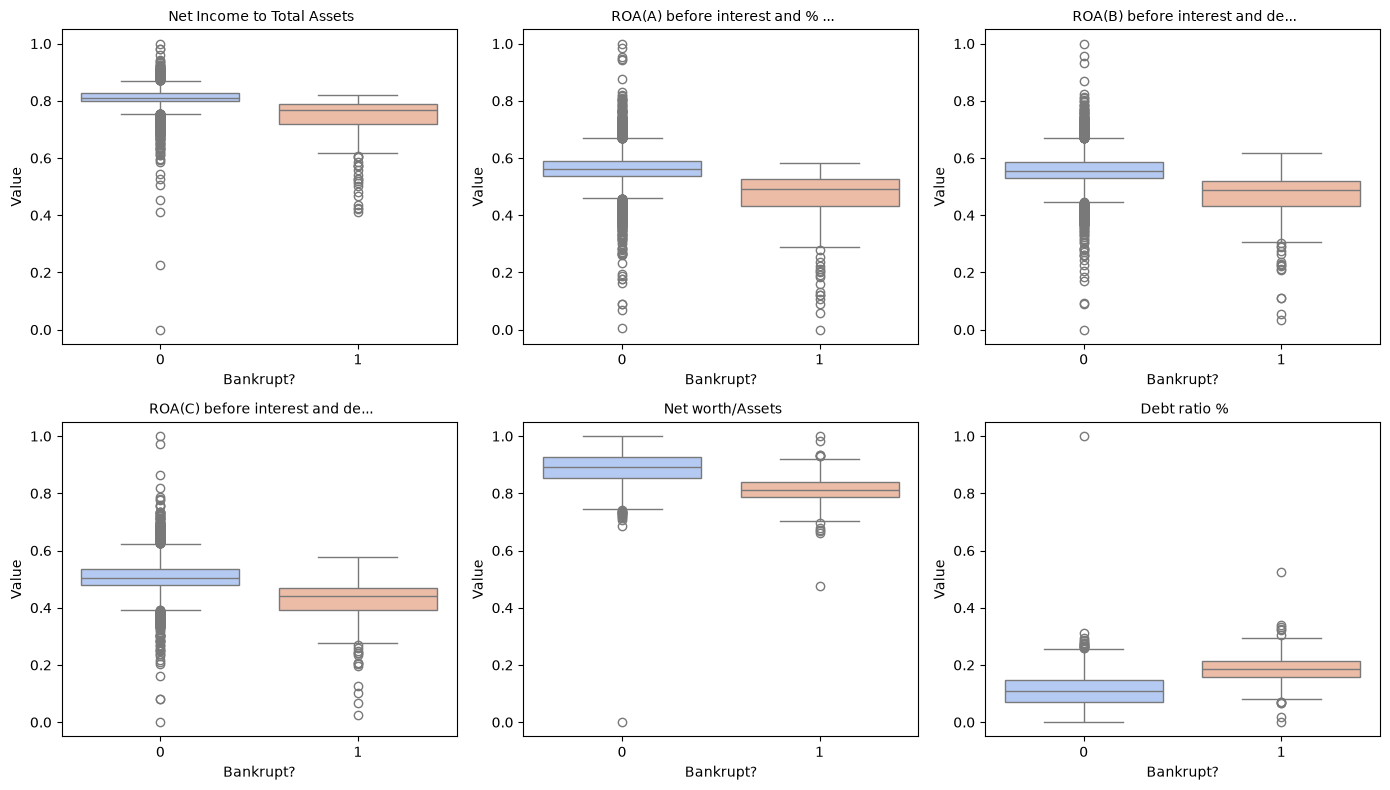

In [86]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau pairplot), dibedakan berdasarkan kelas target.
# Ini membantu melihat apakah ada fitur yang punya batas pemisah yang jelas antar kelas.

target = 'Bankrupt?'

# 1. Ambil 6 fitur dengan korelasi absolut tertinggi terhadap target
top_corr = df.corr(numeric_only=True)[target].abs().drop(target)
top_features = top_corr.nlargest(6).index.tolist()

# 2. Plotting boxplot hanya untuk fitur-fitur pembeda utama
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(14, 8))
axes = axes.flatten()

for idx, col in enumerate(top_features):
    sns.boxplot(x=target, y=col, data=df, ax=axes[idx], palette='coolwarm')
    axes[idx].set_title(col[:30] + '...' if len(col) > 30 else col, fontsize=10)
    axes[idx].set_xlabel("Bankrupt?")
    axes[idx].set_ylabel("Value")

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [87]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

In [138]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).
# Catatan: Decision Tree secara konsep bisa menangani fitur kategorikal secara langsung tanpa One-Hot Encoding,
# tetapi implementasi DecisionTreeClassifier pada scikit-learn tetap mengharuskan input berupa angka.

print("================================")
# cek jumlah fitur kategorikal
categorical_features = df.select_dtypes(include=['object', 'category']).columns.tolist()
print("Fitur kategorikal:", categorical_features)

Fitur kategorikal: []


semua fitur numerik, tidak ada fitur kategorikal. Jadi tidak perlu melakukan encoding.

In [89]:
# Pisahkan fitur (X) dan target (y).
X = df.drop('Bankrupt?', axis=1)
y = df['Bankrupt?']

# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

**Catatan penting:** Decision Tree tidak memerlukan feature scaling (StandardScaler/MinMaxScaler). Split pada Decision Tree dilakukan berdasarkan threshold per fitur satu per satu, bukan berdasarkan jarak antar titik seperti pada KNN atau SVM. Jadi kalian tidak perlu melakukan scaling pada tahap ini.

# 3. Eksperimen Model

## 3.1 Decision Tree dengan Kriteria Gini

Gini Impurity adalah kriteria default pada DecisionTreeClassifier di scikit-learn. Kriteria ini mengukur peluang kesalahan klasifikasi jika sebuah sampel dipilih secara acak dari suatu node.

In [90]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='gini' menggunakan train set.

from sklearn.metrics import classification_report


model = DecisionTreeClassifier(criterion='gini', random_state=42, class_weight='balanced')  # Menambahkan class_weight untuk menangani ketidakseimbangan kelas
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      1320
           1       0.35      0.30      0.32        44

    accuracy                           0.96      1364
   macro avg       0.66      0.64      0.65      1364
weighted avg       0.96      0.96      0.96      1364



In [104]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
predictions = model.predict(X_test)
pd.DataFrame({'predictions': predictions}).to_csv('predictions_gini.csv', index=False)  # Simpan hasil prediksi ke file CSV# Simpan hasil prediksi ke file CSV

#### informasi pohon yg dibuat decision tree gini

In [106]:
print(f"Kedalaman Pohon (Max Depth) : {model.get_depth()}")
print(f"Jumlah Daun (Leaves)        : {model.get_n_leaves()}")
print(f"Total Seluruh Node          : {model.tree_.node_count}")

Kedalaman Pohon (Max Depth) : 65
Jumlah Daun (Leaves)        : 192
Total Seluruh Node          : 383


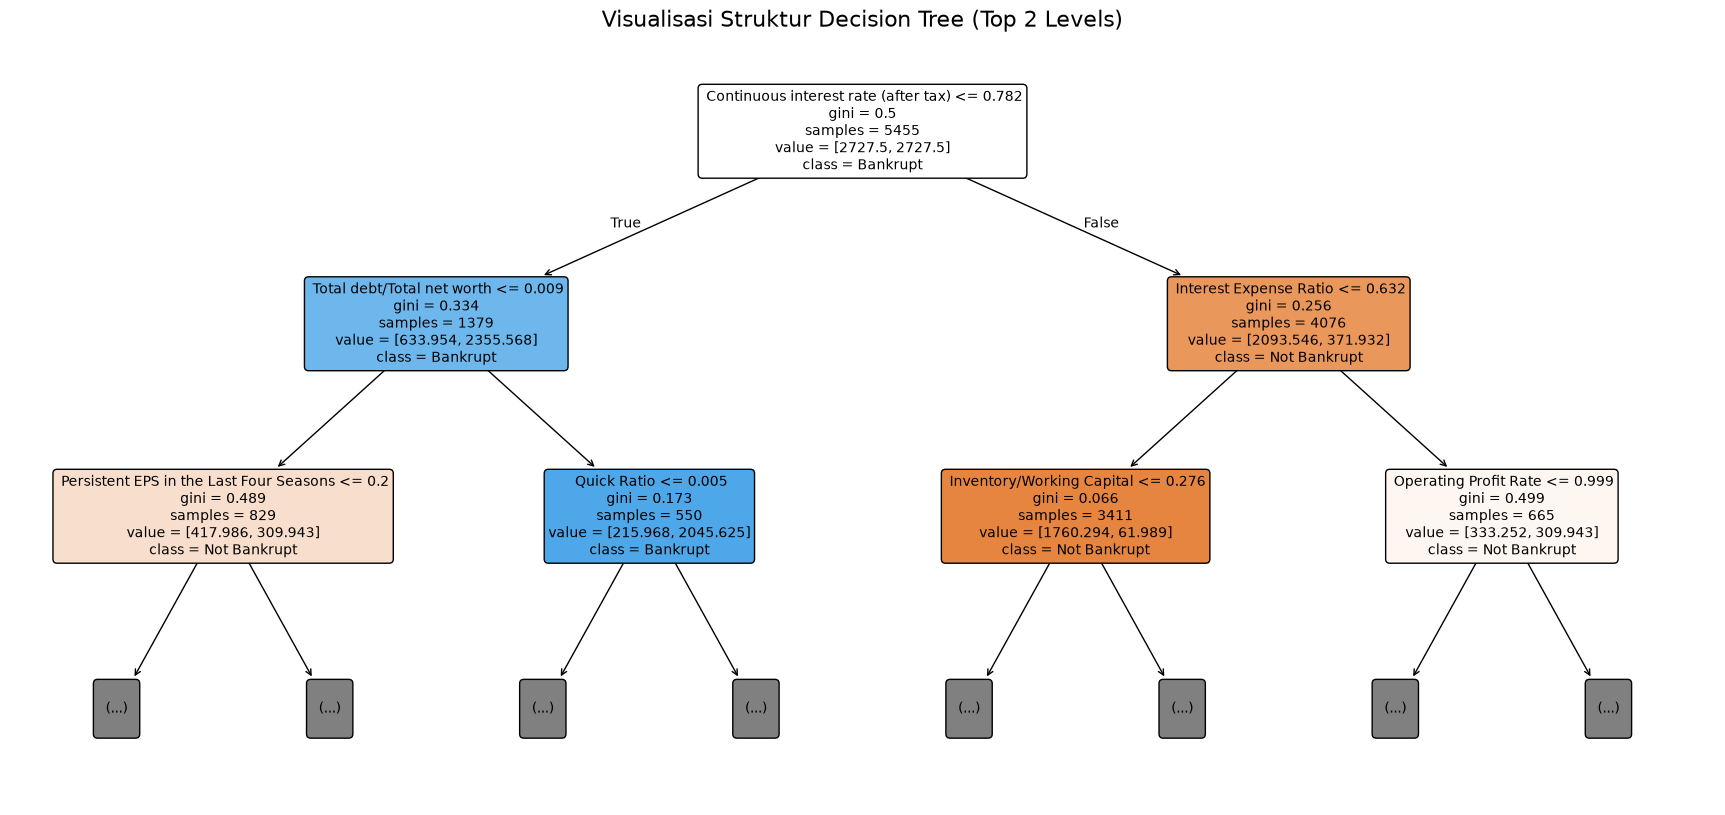

In [107]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=['Not Bankrupt', 'Bankrupt'],
    filled=True,       # Memberi warna: biru/oranye sesuai dominasi kelas
    rounded=True,      # Membuat sudut kotak melengkung
    max_depth=2,       # Sangat disarankan dibatasi (2 atau 3) agar terbaca jelas
    fontsize=10
)

plt.title("Visualisasi Struktur Decision Tree (Top 2 Levels)", fontsize=16)
plt.show()

## 3.2 Decision Tree dengan Kriteria Entropy

Entropy (Information Gain) adalah kriteria alternatif yang mengukur tingkat ketidakpastian distribusi kelas pada suatu node.

In [108]:
# Inisialisasi dan latih model DecisionTreeClassifier dengan criterion='entropy' menggunakan train set.
# Gunakan nilai hyperparameter lain yang sama seperti model Gini di atas, agar perbandingan adil.

model_entropy = DecisionTreeClassifier(criterion='entropy', random_state=42, class_weight='balanced')
model_entropy.fit(X_train, y_train)

print(classification_report(y_test, model_entropy.predict(X_test)))


              precision    recall  f1-score   support

           0       0.98      0.97      0.98      1320
           1       0.33      0.39      0.35        44

    accuracy                           0.95      1364
   macro avg       0.65      0.68      0.67      1364
weighted avg       0.96      0.95      0.96      1364



In [109]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.
model_entropy_predictions = model_entropy.predict(X_test)
pd.DataFrame({'predictions': model_entropy_predictions}).to_csv('predictions_entropy.csv', index=False)  # Simpan hasil prediksi ke file CSV

In [114]:
print(f"Kedalaman Pohon (Max Depth) : {model_entropy.get_depth()}")
print(f"Jumlah Daun (Leaves)        : {model_entropy.get_n_leaves()}")
print(f"Total Seluruh Node          : {model_entropy.tree_.node_count}")

Kedalaman Pohon (Max Depth) : 19
Jumlah Daun (Leaves)        : 148
Total Seluruh Node          : 295


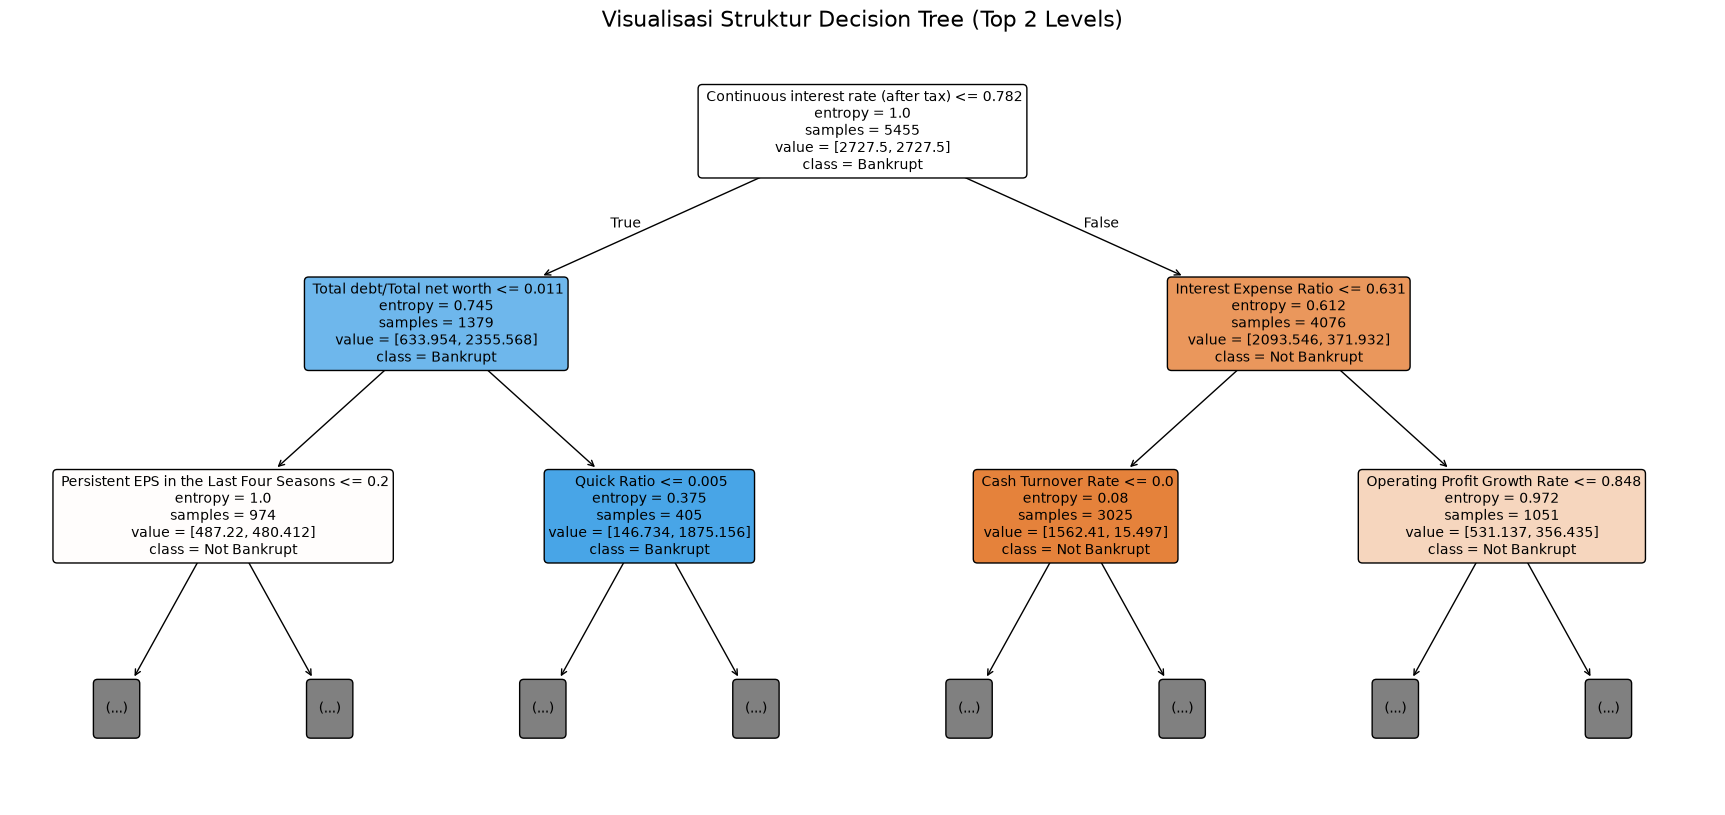

In [115]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    model_entropy,
    feature_names=list(X.columns),
    class_names=['Not Bankrupt', 'Bankrupt'],
    filled=True,       # Memberi warna: biru/oranye sesuai dominasi kelas
    rounded=True,      # Membuat sudut kotak melengkung
    max_depth=2,       # Sangat disarankan dibatasi (2 atau 3) agar terbaca jelas
    fontsize=10
)

plt.title("Visualisasi Struktur Decision Tree (Top 2 Levels)", fontsize=16)
plt.show()

## 3.3 Eksperimen Regularisasi: Pengaruh max_depth terhadap Overfitting

Decision Tree yang dibiarkan tumbuh tanpa batas cenderung overfitting terhadap data training. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai max_depth memengaruhi akurasi training dan testing.

In [116]:
# Latih beberapa model DecisionTreeClassifier dengan variasi nilai max_depth,
# misalnya 1, 2, 3, 5, 10, dan None (tanpa batas kedalaman).
# Gunakan kriteria split terbaik dari salah satu percobaan sebelumnya (Gini atau Entropy).

for depth in [1, 2, 3, 5, 10, None]:
    model_varied = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42, class_weight='balanced')
    model_varied.fit(X_train, y_train)
    y_pred = model_varied.predict(X_test)
    
    print(f"Max Depth: {depth}")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

Max Depth: 1
              precision    recall  f1-score   support

           0       0.99      0.77      0.87      1320
           1       0.11      0.82      0.19        44

    accuracy                           0.77      1364
   macro avg       0.55      0.79      0.53      1364
weighted avg       0.96      0.77      0.85      1364

--------------------------------------------------
Max Depth: 2
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      1320
           1       0.23      0.68      0.34        44

    accuracy                           0.92      1364
   macro avg       0.61      0.80      0.65      1364
weighted avg       0.96      0.92      0.94      1364

--------------------------------------------------
Max Depth: 3
              precision    recall  f1-score   support

           0       1.00      0.83      0.90      1320
           1       0.15      0.89      0.25        44

    accuracy                           0.

In [ ]:
# Hitung akurasi pada train set dan test set untuk setiap nilai max_depth yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

train_accuracies = []
test_accuracies = []

for depth in [1, 2, 3, 5, 10, None]:
    model_varied = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42, class_weight='balanced')
    model_varied.fit(X_train, y_train)
    train_acc = model_varied.score(X_train, y_train)
    test_acc = model_varied.score(X_test, y_test)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)


Text(0.5, 0, 'Max Depth')

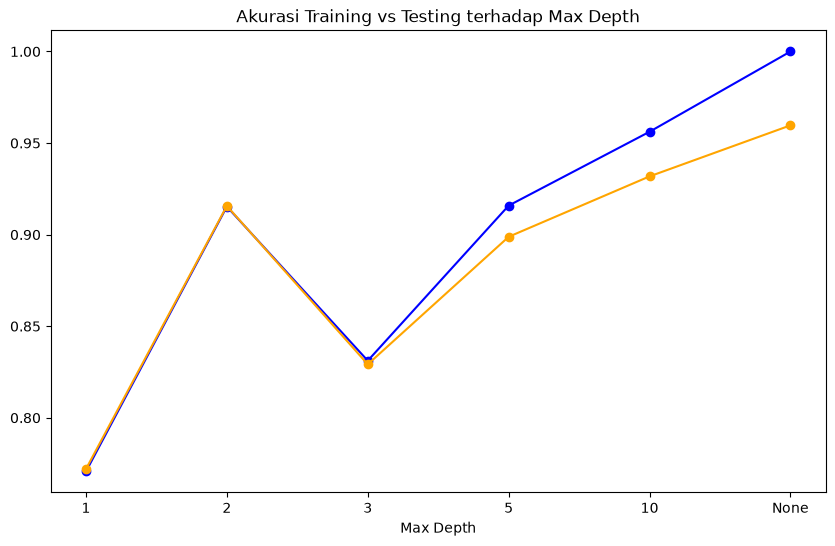

In [118]:
# Plot grafik akurasi training vs testing terhadap max_depth dalam satu chart.
# Amati pada titik berapa model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

depth_values = [1, 2, 3, 5, 10, 'None']
plt.figure(figsize=(10, 6))
plt.plot(depth_values, train_accuracies, marker='o', label='Train Accuracy', color='blue')
plt.plot(depth_values, test_accuracies, marker='o', label='Test Accuracy', color='orange')
plt.title('Akurasi Training vs Testing terhadap Max Depth')
plt.xlabel('Max Depth')

# 4. Evaluasi Model

In [125]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model Gini dan Entropy.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.
snp = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Gini': [model.score(X_test, y_test),
             classification_report(y_test, model.predict(X_test), output_dict=True)['weighted avg']['precision'],
             classification_report(y_test, model.predict(X_test), output_dict=True)['weighted avg']['recall'],
             classification_report(y_test, model.predict(X_test), output_dict=True)['weighted avg']['f1-score']],
    'Entropy': [model_entropy.score(X_test, y_test),
                classification_report(y_test, model_entropy.predict(X_test), output_dict=True)['weighted avg']['precision'],
                classification_report(y_test, model_entropy.predict(X_test), output_dict=True)['weighted avg']['recall'],
                classification_report(y_test, model_entropy.predict(X_test), output_dict=True)['weighted avg']['f1-score']]
})

print(snp)

print()
print("================== who's the winnerr???=====================")
print()
# Tentukan model terbaik untuk tiap metrik
def get_winner(row):
    if row['Gini'] > row['Entropy']:
        return 'Gini'
    elif row['Entropy'] > row['Gini']:
        return 'Entropy'
    else:
        return 'Seri (sama)'

snp['Best Model'] = snp.apply(get_winner, axis=1)
print(snp)

      Metric      Gini   Entropy
0   Accuracy  0.959677  0.954545
1  Precision  0.956468  0.958372
2     Recall  0.959677  0.954545
3   F1-Score  0.957988  0.956370

================== who's the winnerr???=====================

      Metric      Gini   Entropy Best Model
0   Accuracy  0.959677  0.954545       Gini
1  Precision  0.956468  0.958372    Entropy
2     Recall  0.959677  0.954545       Gini
3   F1-Score  0.957988  0.956370       Gini


### pemenang 
Dari metric tersebut, **gini** menunjukkan peforma yang lebih baik pada 3 dari 4 metric, sedangkan entropy hanya lebih baik pada precision.

Text(0.5, 1.0, 'Confusion Matrix - Entropy')

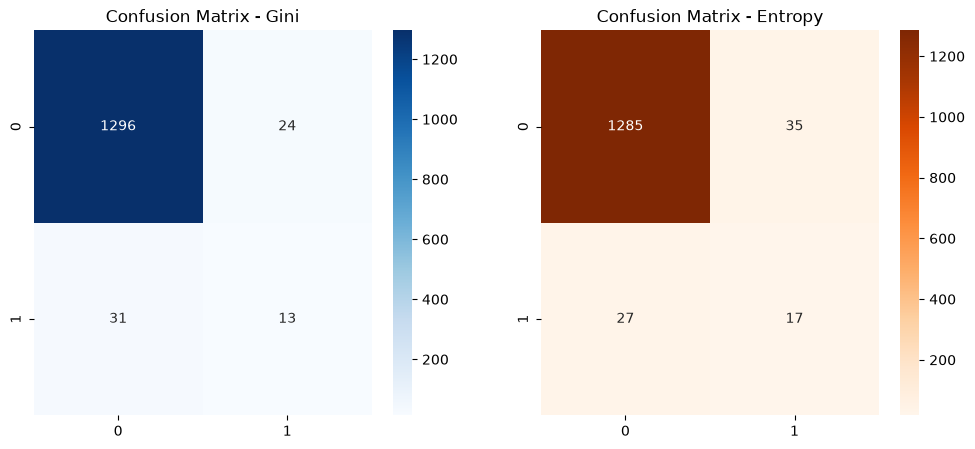

In [128]:
# Tampilkan Confusion Matrix untuk model Gini dan Entropy dalam bentuk heatmap.
# Susun keduanya dalam satu baris subplot.
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(12, 5))
sns.heatmap(confusion_matrix(y_test, model.predict(X_test)), annot=True, fmt='d', cmap='Blues', ax=plt.subplot(1, 2, 1))
plt.title('Confusion Matrix - Gini')
plt.subplot(1, 2, 2)
sns.heatmap(confusion_matrix(y_test, model_entropy.predict(X_test)), annot=True, fmt='d', cmap='Oranges', ax=plt.subplot(1, 2, 2))
plt.title('Confusion Matrix - Entropy')

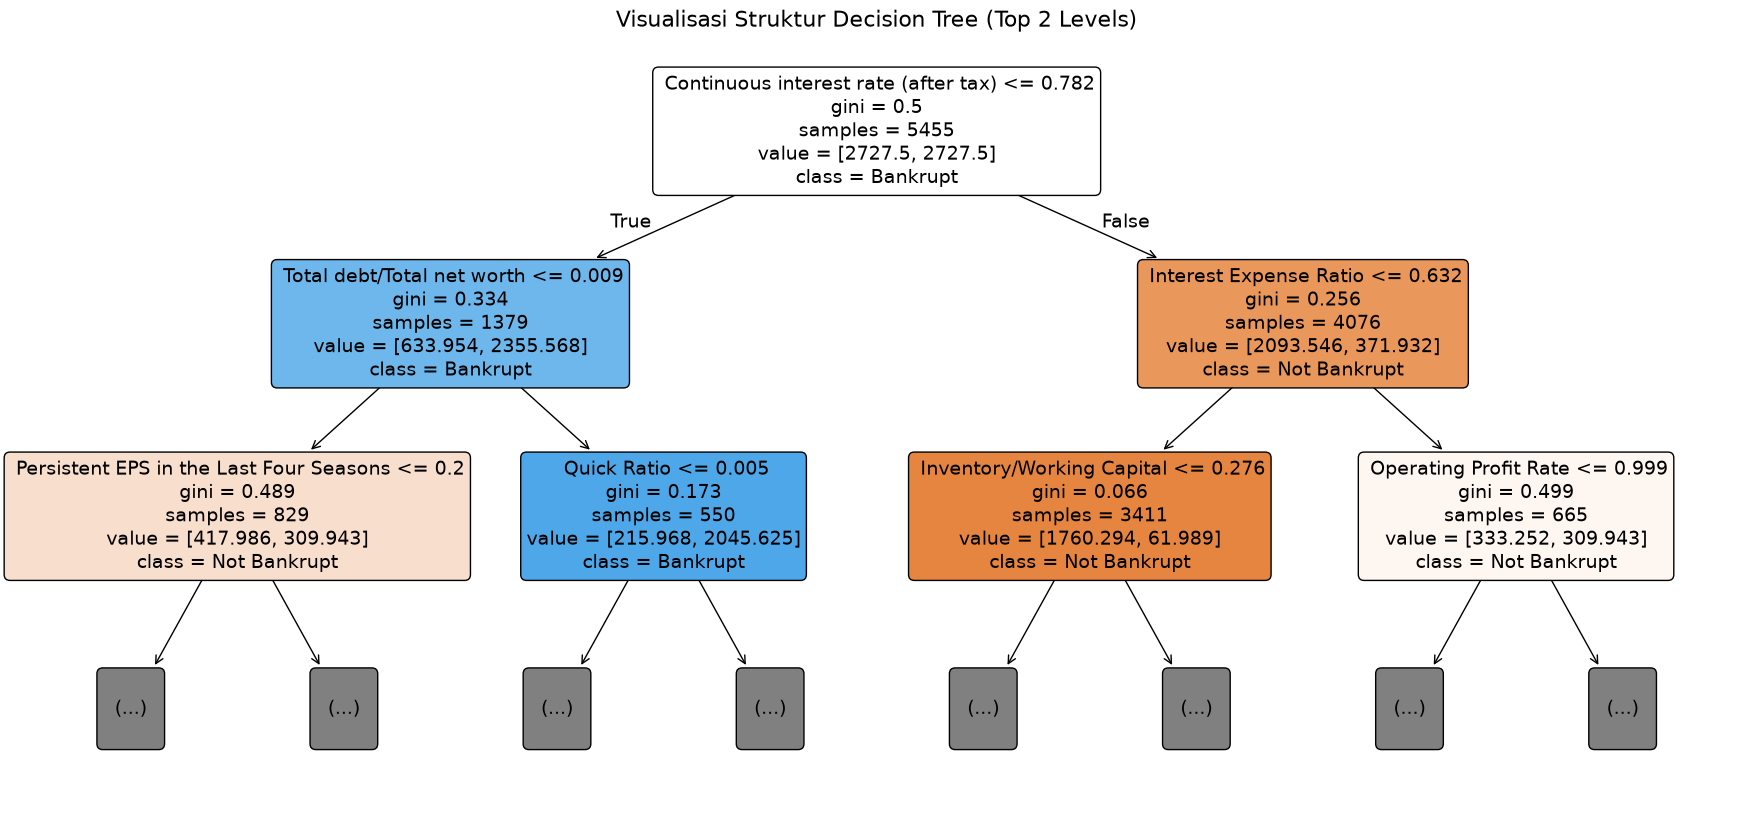

In [129]:
# Visualisasikan struktur Decision Tree (gunakan plot_tree) untuk model dengan performa terbaik.
# Batasi kedalaman visualisasi (misalnya max_depth=2 atau 3 pada parameter plot_tree) agar tetap mudah dibaca.
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(22, 10))

plot_tree(
    model,
    feature_names=list(X.columns),
    class_names=['Not Bankrupt', 'Bankrupt'],
    filled=True,       # Memberi warna: biru/oranye sesuai dominasi kelas
    rounded=True,      # Membuat sudut kotak melengkung
    max_depth=2,       # Sangat disarankan dibatasi (2 atau 3) agar terbaca jelas
    fontsize=14
)

plt.title("Visualisasi Struktur Decision Tree (Top 2 Levels)", fontsize=16)
plt.show()


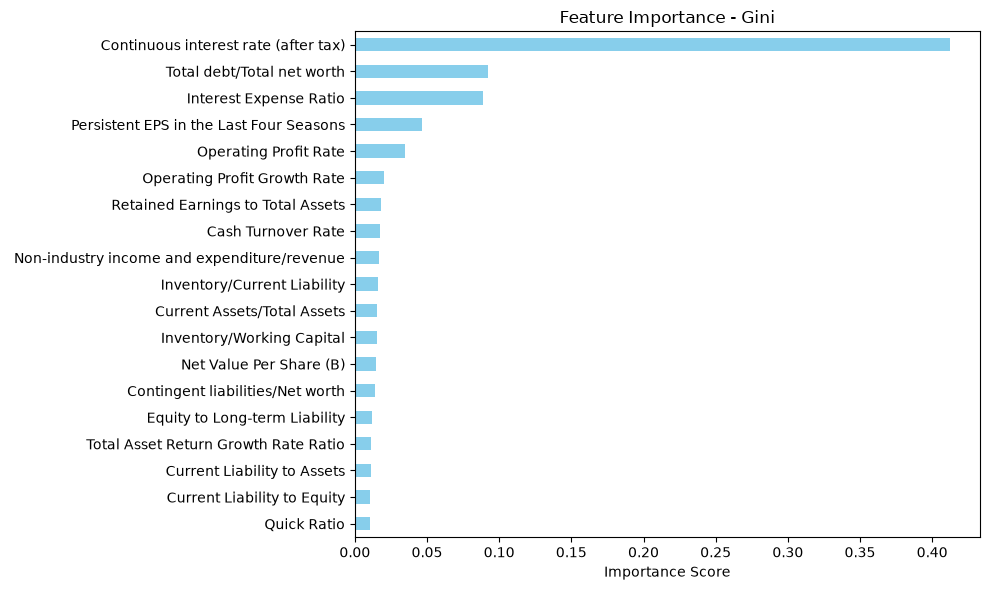

In [137]:
plt.figure(figsize=(10, 6))
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
feature_importances = feature_importances[(feature_importances > 0.01)]  #dari 0.01 biar ga terlalu banyak
feature_importances.sort_values(ascending=True).plot(kind='barh', color='skyblue')
plt.title('Feature Importance - Gini')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa Decision Tree dengan kriteria Gini vs Entropy. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?

Answer: berdasarkan hasil eksperimen yang telah dilakukan, performa Decision Tree dengan kriteria Gini dan Entropy menunjukkan perbedaan yang tidak signifikan dalam hal akurasi. Hal ini mungkin disebabkan oleh karakteristik dataset yang digunakan, di mana distribusi kelas dan fitur-fitur yang ada tidak memberikan keuntungan yang jelas bagi salah satu class.

- Jelaskan temuan dari eksperimen regularisasi (max_depth). Pada nilai berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?

Answer: Dari gambar grafik akurasi training vs testing terhadap max_depth, terlihat bahwa model mulai menunjukkan gejala overfitting pada nilai max_depth = 5. Pada tiitk tersebut, akurasi training terus meningkat dan melampaui akurasi testing yang peningkatannya tidak sebanding.

- Fitur apa yang paling berpengaruh terhadap prediksi model, berdasarkan feature importance?

Answer: Berdasarkan feature importance, fitur yang paling berpengaruh (feature importance = 0.4) adalah `Continuous interest rate (after tax)`. fitur tersebut memilki pengearuh yg jauh lebih tinggi dibandingkan fitur lain, sehingga model mungkin cenderung mengandalkan fitur ini untuk membuat prediksi

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba pruning dengan ccp_alpha, membandingkan dengan model lain, atau mencoba variasi hyperparameter lain seperti min_samples_leaf), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

### 6.1 Kesimpulan

1. **Kriteria Split (Gini vs Entropy):**
   * Performa Decision Tree dengan kriteria Gini dan Entropy tidak menunjukkan perbedaan signifikan.
   * Model Gini mencatat Accuracy 0.9597, Recall 0.9597, dan F1-Score 0.9580, sedangkan Entropy mencatat Precision 0.9584.

2. **Regularisasi `max_depth`:**
   * Model tanpa pembatasan kedalaman (`max_depth=None`) menghasilkan pohon dengan kedalaman 65 dan 192 daun.
   * Selisih antara akurasi training dan testing mulai melebar pada `max_depth = 5`, di mana akurasi training terus meningkat sementara akurasi testing cenderung stagnan (indikasi awal overfitting).

3. **Feature Importance:**
   * Fitur dengan nilai importance tertinggi pada model Gini adalah `Continuous interest rate (after tax)` dengan nilai sekitar 0.40.

4. **Kinerja pada Kelas Minoritas:**
   * Penggunaan `class_weight='balanced'` pada model tanpa pembatasan kedalaman (`max_depth=None`) menghasilkan Recall sebesar 0.30 untuk kelas 1 (bangkrut).

---

### 6.2 Saran

1. **Pengaturan Hyperparameter:**
   * Menguji kombinasi parameter pemangkasan seperti `min_samples_leaf`, `min_samples_split`, atau pruning dengan `ccp_alpha` untuk mengontrol ukuran pohon.
2. **Metode Penanganan Imbalance:**
   * Menguji metode resampling pada data training (seperti oversampling atau undersampling) untuk mengamati pengaruhnya terhadap Recall kelas minoritas.
3. **Model Pembanding:**
   * Membandingkan performa Decision Tree tunggal dengan algoritma lain, seperti Random Forest, pada dataset yang sama.